# Thick crystals: the multislice method

A thin crystal's high-resolution image follows its **projected potential**: the potential of
its atoms added up along the beam. That holds while the electron wave is scattered only once on
its way through. In a thicker crystal it's scattered again and again, the beams it scatters into
exchange intensity with each other, and the image and the diffraction pattern change with the
thickness. The **multislice method** follows the wave through the crystal slice by slice. This
notebook shows how, with silicon along [110], step by step. It follows the
*crystal_thickness.py* sample.

You'll:

1. read a refined silicon structure and see how it repeats on the map and along the beam;
2. compare the projection with the multislice, and see where they part;
3. choose the slice thickness and the pixel size, and see what each costs and buys;
4. follow the beams' intensities through the crystal, and check them against emaps' Bloch-wave
   calculation;
5. make HREM images and convergent-beam diffraction (CBED) patterns at several thicknesses.

**How it works.** The crystal is cut into thin slices along the beam. Each slice changes the
wave's phase by $\sigma V_n(\mathbf r)$, with $V_n$ the slice's projected potential and
$\sigma$ the interaction constant; then the wave travels to the next slice, which in reciprocal
space multiplies it by the Fresnel propagator $\exp(-i\pi\lambda\,\Delta z\,k^2)$. The crystal
repeats along the beam, so the slices of one repeat serve for every repeat. emaps computes
everything: each slice's potential from its atoms, the transmission functions and the
propagation.

**A licensed feature.** The multislice needs an activated pyEMAPS license. `pyemaps -l trial`,
run in a terminal with an internet connection, activates a free 7-day trial; for a full license,
contact support@emlabsoftware.com. Step 1 checks it.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment. Every step runs in seconds; Step 8's large maps take about ten.

The [thick crystals guide](https://emlab-solutions.github.io/pyemaps/user_guide/probe/multislice.html)
covers the same ground, and the [probe notebook](probe.ipynb) the lenses
used here.

## Step 1: Import pyEMAPS and check the license

`Probe` holds the lens and the map, as in the probe notebook, and has the multislice methods.

In [1]:
import os
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt

import pyemaps
from pyemaps import Crystal, EMC, SIMC, Probe, stem4d

print('pyEMAPS', version('pyemaps'))
if stem4d.check_license_once() == stem4d.LICENSE_ACTIVE:
    print('License: active')
else:
    print('No active license: run "pyemaps -l trial" in a terminal for a 7-day trial, '
          'or contact support@emlabsoftware.com.')

pyEMAPS 2.9.0
License: active


## Step 2: The crystal

The silicon is a refined crystal structure from the
[Crystallography Open Database](https://www.crystallography.net) (COD entry 2102763), with its
measured thermal factor. Its CIF file comes with the samples, and `Crystal.from_cif` reads it.

`crystal_repeats` tells how the crystal repeats along [110]: across the map, every $a$ along
[001] and every $a/\sqrt2$ along [1$\bar1$0], and along the beam every $a/\sqrt2$ too, since the
face-centring halves the [110] cell vector. The map repeats itself at its edges, so it should hold
a whole number of the repeats both ways; `sizes` lists the map sizes that do, with the strain
`fit=True` needs to close the last gap.

In [2]:
silicon = Crystal.from_cif(os.path.join(os.path.dirname(pyemaps.__file__), 'samples',
                                        'Si_COD_2102763.cif'))
silicon.name = 'Silicon'          # a CIF names it after its COD entry
a = float(silicon.cell.a)
ZONE = (1, 1, 0)

r = Probe().crystal_repeats(silicon, zone=ZONE, max_size=70)
print(f'a = {a} Å')
print('repeats across the map (Å):', [round(float(np.hypot(*v)), 4) for v in r['repeats']])
print(f'repeat along the beam: {r["period"]:.4f} Å')
print('seam-free map sizes (Å, strain):', [(round(s, 2), f'{100 * e:.2f}%') for s, e in r['sizes']])


Info: closest matching space group information found in pyemaps: [(227, 2)]


a = 5.42712 Å
repeats across the map (Å): [3.8376, 5.4271]
repeat along the beam: 3.8376 Å
seam-free map sizes (Å, strain): [(65.13, '0.17%'), (65.24, '0.17%')]


$12a$ = 65.1 Å holds 12 repeats across and 17 down, within 0.17%. The maps below use it, with
`fit=True`.

## Step 3: Projection or multislice

`crystal_potential` gives the projected potential, and `exit_wave` its transmission function: the
whole slab as one slice. `crystal_exit_wave` is the multislice, here with slices of about 2 Å. At a
single repeat, 3.8 Å, the two agree; at 100 Å they don't. Below, the HREM images of a corrected
lens from each.

   3.8 Å: correlation of the two images 1.000


 100.0 Å: correlation of the two images 0.906


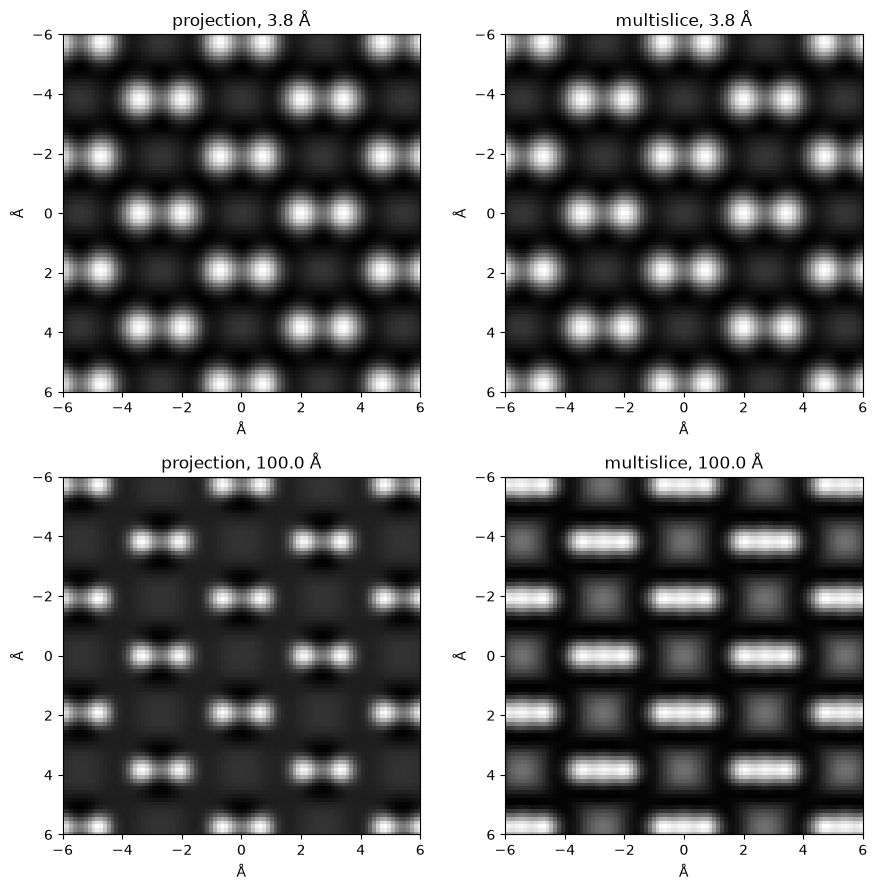

In [3]:
MAP = {'size': 12 * a, 'sampling': 512}
lens = Probe(kv=200, cs=-0.013, defocus=7.0, aperture=40.0, cc=1.5, energy_spread=0.7,
             semi_angle=0.2, **MAP)

def corr(x, y):
    return np.corrcoef(x.ravel(), y.ravel())[0, 1]

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for row, t in enumerate((r['period'], 100.0)):
    projected = lens.hrem(lens.exit_wave(lens.crystal_potential(silicon, zone=ZONE,
                                                                thickness=t, fit=True)))
    sliced = lens.hrem(lens.crystal_exit_wave(silicon, zone=ZONE, thickness=t, fit=True))
    for ax, img, name in zip(axes[row], (projected, sliced), ('projection', 'multislice')):
        lens.show(img, 'hrem', ax=ax, title=f'{name}, {t:.1f} Å')
        ax.set_xlim(-6, 6)
        ax.set_ylim(6, -6)
    print(f'{t:6.1f} Å: correlation of the two images {corr(projected, sliced):.3f}')
plt.tight_layout()
plt.show()

At one repeat the images are the same; at 100 Å the projection still shows dumbbells, while the
multislice, which lets the beams exchange intensity on the way through, shows bars.

## Step 4: How thin the slices

`slice_thickness` sets roughly how thick each slice is; the crystal's repeat along the beam is cut
into a whole number of slices. Thinner slices follow the wave more closely and take longer. Here
the direct beam's intensity at 300 Å, and how far each image is from the one with the thinnest
slices:

In [4]:
import time

results = {}
for dz in (3.84, 1.92, 0.96, 0.48):
    start = time.perf_counter()
    wave = lens.crystal_exit_wave(silicon, zone=ZONE, thickness=300, slice_thickness=dz,
                                  fit=True)
    results[dz] = (wave, time.perf_counter() - start)
finest = lens.hrem(results[0.48][0])
for dz, (wave, seconds) in results.items():
    direct = abs(np.fft.fft2(wave)[0, 0] / wave.size) ** 2
    print(f'slices of {dz:4.2f} Å: direct beam {direct:.4f}, image correlation with 0.48 Å '
          f'{corr(lens.hrem(wave), finest):.4f}, {seconds:.2f} s')

slices of 3.84 Å: direct beam 0.8156, image correlation with 0.48 Å 0.9991, 0.24 s
slices of 1.92 Å: direct beam 0.8158, image correlation with 0.48 Å 0.9999, 0.46 s
slices of 0.96 Å: direct beam 0.8158, image correlation with 0.48 Å 1.0000, 0.69 s
slices of 0.48 Å: direct beam 0.8158, image correlation with 0.48 Å 1.0000, 1.26 s


The default, about 2 Å, is within a percent of the thinnest slices. One slice per repeat (3.8 Å)
is coarser; halving the default changes nothing visible and takes over twice as long.

## Step 5: How fine the pixels

The slices are band-limited to 2/3 of the map's largest spatial frequency, `sampling / (2 * size)`,
so their products don't alias. What the crystal scatters beyond that limit is lost, so the wave's
total intensity drops below 1. Thick crystals need fine pixels:

In [5]:
for sampling in (256, 512, 1024):
    probe = Probe(kv=200, size=12 * a, sampling=sampling)
    wave = probe.crystal_exit_wave(silicon, zone=ZONE, thickness=300, fit=True)
    limit = 2 / 3 * sampling / (2 * probe.size)
    print(f'{sampling:5d} pixels of {probe.size / sampling:.3f} Å: band limit {limit:.2f} 1/Å, '
          f'intensity kept at 300 Å {np.mean(abs(wave) ** 2):.4f}')

  256 pixels of 0.254 Å: band limit 1.31 1/Å, intensity kept at 300 Å 0.9221


  512 pixels of 0.127 Å: band limit 2.62 1/Å, intensity kept at 300 Å 0.9920


 1024 pixels of 0.064 Å: band limit 5.24 1/Å, intensity kept at 300 Å 1.0000


## Step 6: Thickness fringes, and a check against Bloch waves

A list of thicknesses gives the wave at each from one pass through the crystal. Along [001] the
map is $8a$ across both ways, so each beam $(hk0)$ falls on one pixel of the wave's Fourier
transform, at $(8k, 8h)$, and its intensity can be read off. As the crystal gets thicker,
intensity moves from the direct beam into the diffracted ones and back: the **thickness fringes**,
or Pendellösung.

emaps' Bloch-wave method solves the same problem in a different way, from the crystal's
structure factors, and `getSCMatrix` gives its beams' amplitudes at a thickness. The dots are
Bloch waves at the exact zone axis; it includes absorption, which the multislice here doesn't,
and fewer beams, so they part slowly with thickness.

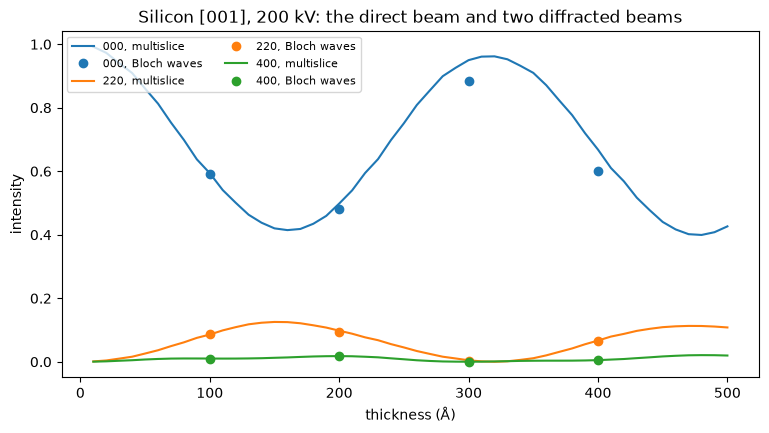

100 Å: 000 0.5939 / 0.5923, 220 0.0858 / 0.0864, 400 0.0102 / 0.0101
200 Å: 000 0.4982 / 0.4806, 220 0.0980 / 0.0931, 400 0.0179 / 0.0170
300 Å: 000 0.9499 / 0.8838, 220 0.0047 / 0.0032, 400 0.0002 / 0.0002
400 Å: 000 0.6682 / 0.6021, 220 0.0669 / 0.0647, 400 0.0052 / 0.0050


In [6]:
q = Probe(kv=200, size=8 * a, sampling=256)
thick = np.arange(10, 510, 10)
waves = q.crystal_exit_wave(silicon, zone=(0, 0, 1), thickness=thick, x_axis=(1, 0, 0))
F = np.abs(np.fft.fft2(waves) / waves[0].size) ** 2
beams = {'000': (0, 0), '220': (2, 2), '400': (4, 0)}
curves = {name: F[:, (8 * k) % 256, (8 * h) % 256] for name, (h, k) in beams.items()}

bloch_t = [100, 200, 300, 400]
bloch = {name: [] for name in beams}
silicon.beginBloch(sampling=2, em_controls=EMC(zone=(0, 0, 1), vt=200, simc=SIMC(gmax=2.0)))
try:
    for t in bloch_t:
        n, scm, ev, hkl = silicon.getSCMatrix(ib_coords=(0, 0), sample_thickness=t)
        hkl = np.asarray(hkl)
        hkl = hkl if hkl.shape[-1] == 3 else hkl.T
        index = {tuple(int(v) for v in b): i for i, b in enumerate(hkl)}
        amp = np.asarray(scm)[:, index[(0, 0, 0)]]
        for name, (h, k) in beams.items():
            bloch[name].append(abs(amp[index[(h, k, 0)]]) ** 2)
finally:
    silicon.endBloch()

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, colour in zip(beams, ('C0', 'C1', 'C2')):
    ax.plot(thick, curves[name], colour, label=f'{name}, multislice')
    ax.plot(bloch_t, bloch[name], 'o', color=colour, label=f'{name}, Bloch waves')
ax.set_xlabel('thickness (Å)')
ax.set_ylabel('intensity')
ax.set_title('Silicon [001], 200 kV: the direct beam and two diffracted beams')
ax.legend(fontsize=8, ncol=2)
plt.show()
for i, t in enumerate(bloch_t):
    k = list(thick).index(t)
    print(f'{t} Å: ' + ', '.join(f'{name} {curves[name][k]:.4f} / {bloch[name][i]:.4f}'
                                 for name in beams))

The two methods follow the same fringes; up to 200 Å they agree within about 5%, and further
out the Bloch waves' absorption makes them lower.

## Step 7: HREM images through the thickness

The corrected lens of Step 3, at 20, 100 and 300 Å, from one pass:

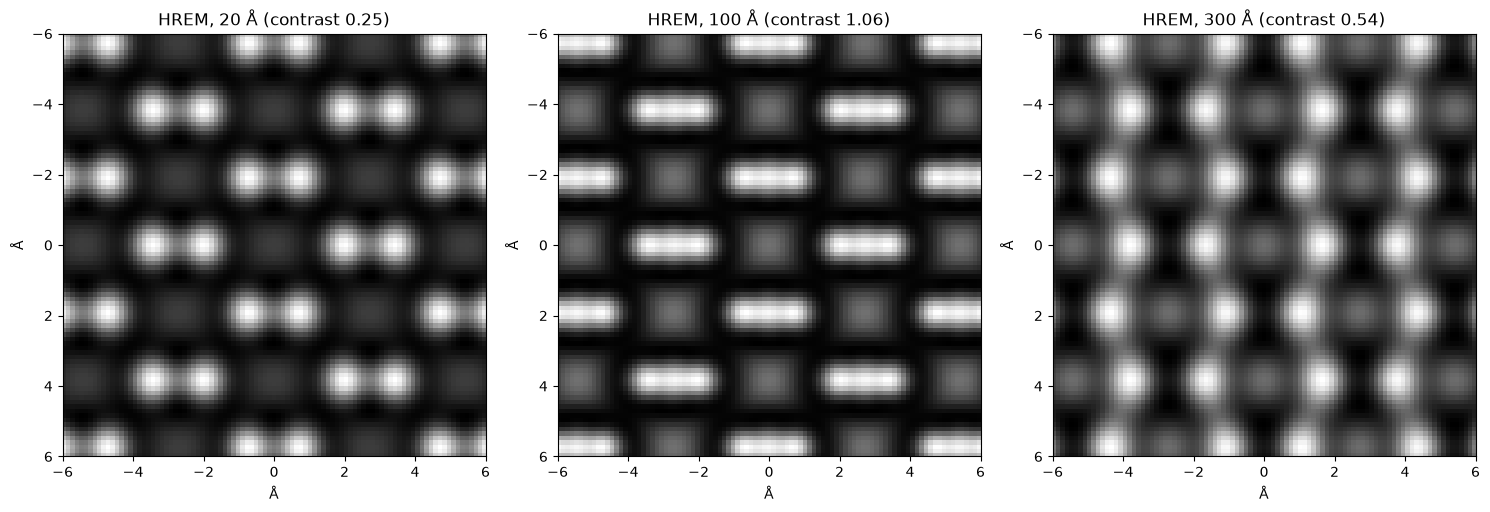

In [7]:
thicknesses = [20, 100, 300]
waves = lens.crystal_exit_wave(silicon, zone=ZONE, thickness=thicknesses, fit=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, t, wave in zip(axes, thicknesses, waves):
    image = lens.hrem(wave)
    lens.show(image, 'hrem', ax=ax, title=f'HREM, {t} Å (contrast {image.std() / image.mean():.2f})')
    ax.set_xlim(-6, 6)
    ax.set_ylim(6, -6)
plt.tight_layout()
plt.show()

At 20 Å the dumbbells, two columns 1.36 Å apart, are resolved; at 100 Å they've merged into bars,
and at 300 Å the pattern has changed again. In a thick crystal, what an image shows depends on
the thickness as much as on the lens: comparing an experimental image with a thickness series
like this one is how its thickness is found.

## Step 8: Convergent-beam diffraction through the thickness

`crystal_ronchigram` sends a probe through the crystal and records the pattern in the far field.
With a small aperture (3 mrad, so the disks don't overlap) and the probe focused on the crystal,
it's a **CBED pattern**. A larger map gives finer angles, since each pixel is `1 / size`: here
$24a$ with 1024 pixels, 0.19 mrad per pixel.

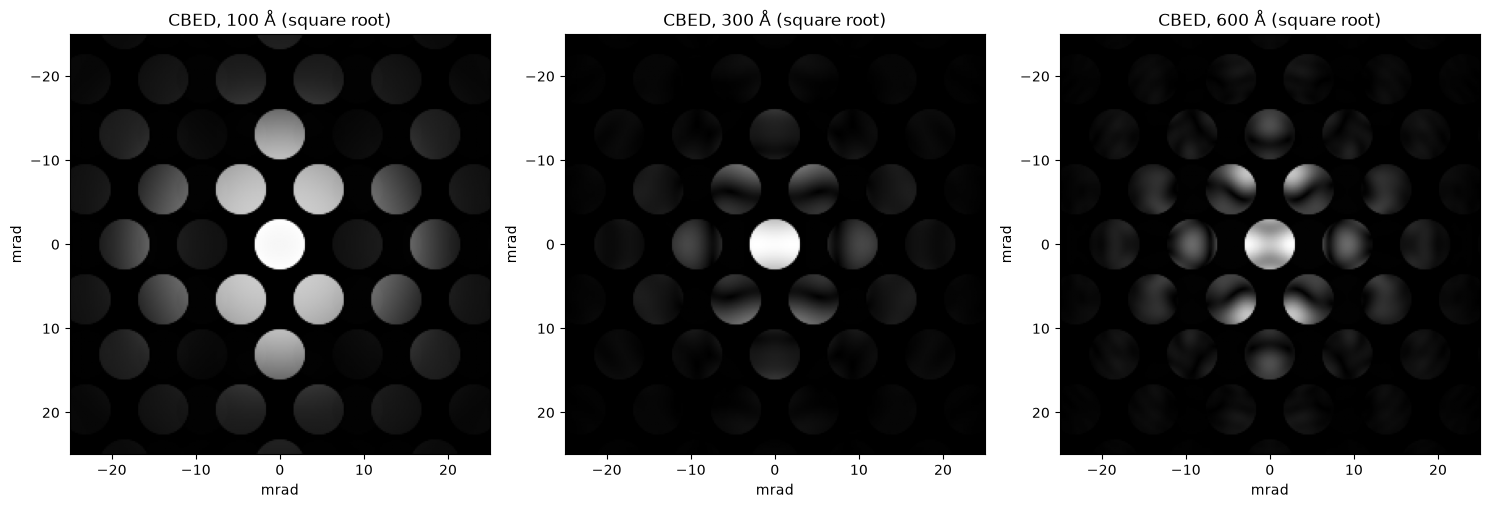

In [8]:
cbed = Probe(kv=200, aperture=3.0, cs=1.2, defocus=0.0, size=24 * a, sampling=1024)
thicknesses = [100, 300, 600]
patterns = cbed.crystal_ronchigram(silicon, zone=ZONE, thickness=thicknesses, fit=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, t, pattern in zip(axes, thicknesses, patterns):
    cbed.show(np.sqrt(pattern), 'ronchigram', ax=ax, aperture=False,
              title=f'CBED, {t} Å (square root)')
    ax.set_xlim(-25, 25)
    ax.set_ylim(25, -25)
plt.tight_layout()
plt.show()

At 100 Å the disks are nearly uniform; at 300 and 600 Å fringes appear inside them, as each
direction through the disk sees a slightly different excitation of the beams. Matching these
fringes with an experimental pattern is a precise way to measure thickness.

## Try it yourself

1. **Another zone axis.** Repeat Step 7 along `ZONE = (0, 0, 1)` with `size=12 * a`: along [001]
   the repeat is $a$ both ways, so the map has no seam even without `fit`.
2. **Thickness from fringes.** In Step 6, at what thickness does the direct beam first reach its
   minimum? That's the extinction distance of the strongest beams along [001].
3. **The slices again.** Repeat Step 4 at 600 Å. Do coarse slices go wrong faster in a thicker
   crystal?
4. **Defocus.** In Step 7, change the lens's `defocus` by ±5 nm at 100 Å. When could the image of a
   thin crystal at one defocus be mistaken for a thicker one at another?
5. **Another crystal.** Read a CIF of your own with `Crystal.from_cif` and make its HREM thickness
   series. Check `crystal_repeats` first for a map size that fits.

## Next

- The [probe notebook](probe.ipynb): the lenses used here, probes, Ronchigrams, the CTF and HREM
  images, and the projected potential of a thin crystal.
- The [thick crystals guide](https://emlab-solutions.github.io/pyemaps/user_guide/probe/multislice.html),
  and the reference for
  [`crystal_exit_wave`](https://emlab-solutions.github.io/pyemaps/api/probe.html#pyemaps.probe.Probe.crystal_exit_wave).

## Further reading

- J. M. Cowley and A. F. Moodie, *The scattering of electrons by atoms and crystals. I. A new
  theoretical approach*, Acta Crystallographica 10, 609 (1957): the multislice method.
- E. J. Kirkland, *Advanced Computing in Electron Microscopy* (Springer): the multislice as
  emaps implements it, the band limit, and sampling.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- the dynamical theory of electron diffraction, behind the thickness fringes and the Bloch
  waves of Step 6.